<a href="https://colab.research.google.com/github/juleuzun/Python_DataScience_Bootcamp/blob/main/Lessons/Lesson_07_logistic_regression_knn_svm_ann_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression

In [1]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [3]:
X, y = make_classification(
    n_samples=1000,
    n_informative=2,
    n_features=5,
    n_classes=2,
    random_state=42
)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [5]:
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)

LogisticRegression()

In [6]:
y_pred = lr_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy score: ", accuracy)

Accuracy score:  0.89


# KNN - K- Nearest Neighbors

In [7]:
from sklearn.neighbors import KNeighborsClassifier

In [8]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [10]:
y_pred = knn_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy score: ", accuracy)

Accuracy score:  0.9033333333333333


# SVM (Support Vector Machine) - SVR (Support Vector Regression)


In [11]:
from sklearn.svm import SVC

In [12]:
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

SVC(kernel='linear')

In [13]:
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy score: ", accuracy)

Accuracy score:  0.8866666666666667


# ANN - Artificial Neural Network

In [27]:
import pandas as pd

In [28]:
dataset_path = 'https://raw.githubusercontent.com/juleuzun/Python_DataScience_Bootcamp/refs/heads/main/Datasets/Lesson_07_breast_cancer.data'

In [29]:
data = pd.read_csv(dataset_path, header=None)

In [30]:
column_name = data.iloc[0]

In [31]:
print(column_name)
print(data.head(10))

0    30
1    64
2     1
3     1
Name: 0, dtype: int64
    0   1   2  3
0  30  64   1  1
1  30  62   3  1
2  30  65   0  1
3  31  59   2  1
4  31  65   4  1
5  33  58  10  1
6  33  60   0  1
7  34  59   0  2
8  34  66   9  2
9  34  58  30  1


In [34]:
data.columns = ["Age", "Operation_Year", "Axillary_Nodes", "Survival_Status"]
print(data.head(10))

   Age  Operation_Year  Axillary_Nodes  Survival_Status
0   30              64               1                1
1   30              62               3                1
2   30              65               0                1
3   31              59               2                1
4   31              65               4                1
5   33              58              10                1
6   33              60               0                1
7   34              59               0                2
8   34              66               9                2
9   34              58              30                1


In [35]:
data.loc[data['Survival_Status'] == 2, 'Survival_Status'] = 0
print(data.head(10))

   Age  Operation_Year  Axillary_Nodes  Survival_Status
0   30              64               1                1
1   30              62               3                1
2   30              65               0                1
3   31              59               2                1
4   31              65               4                1
5   33              58              10                1
6   33              60               0                1
7   34              59               0                0
8   34              66               9                0
9   34              58              30                1


In [36]:
data['Survival_Status'] = data['Survival_Status'].astype('int64')
print(data.dtypes)

Age                int64
Operation_Year     int64
Axillary_Nodes     int64
Survival_Status    int64
dtype: object


In [39]:
from sklearn.preprocessing import MinMaxScaler

X = data.drop('Survival_Status', axis=1)
y = data['Survival_Status']

In [41]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
X = pd.DataFrame(X, columns=['Age', 'Operation_Year', 'Axillary_Nodes'])
print(X.head(10))

        Age  Operation_Year  Axillary_Nodes
0  0.000000        0.545455        0.019231
1  0.000000        0.363636        0.057692
2  0.000000        0.636364        0.000000
3  0.018868        0.090909        0.038462
4  0.018868        0.636364        0.076923
5  0.056604        0.000000        0.192308
6  0.056604        0.181818        0.000000
7  0.075472        0.090909        0.000000
8  0.075472        0.727273        0.173077
9  0.075472        0.000000        0.576923


In [43]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state=42)

In [45]:
from keras.models import Sequential
from keras.layers import Dense

In [46]:
print(X_train.shape)

(244, 3)


In [47]:
ann_model = Sequential()

In [51]:
ann_model.add(Dense(128,input_shape=(X_train.shape[1],),activation='relu'))
ann_model.add(Dense(64,activation='relu'))
ann_model.add(Dense(32,activation='relu'))
ann_model.add(Dense(16,activation='relu'))
ann_model.add(Dense(1,activation='relu'))
ann_model.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [53]:
ann_model.fit(X_train, y_train, epochs=10000,verbose=0)

In [54]:
loss, accuracy = ann_model.evaluate(X_test, y_test)
print("Loss: ", loss)
print("Accuracy: ", accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2903 - loss: 11.4386 
Loss:  11.438648223876953
Accuracy:  0.29032257199287415


# K-MEANS CLUSTERING

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

In [58]:
X,_=make_blobs(
    n_samples=300,
    centers=4,
    random_state=42
)

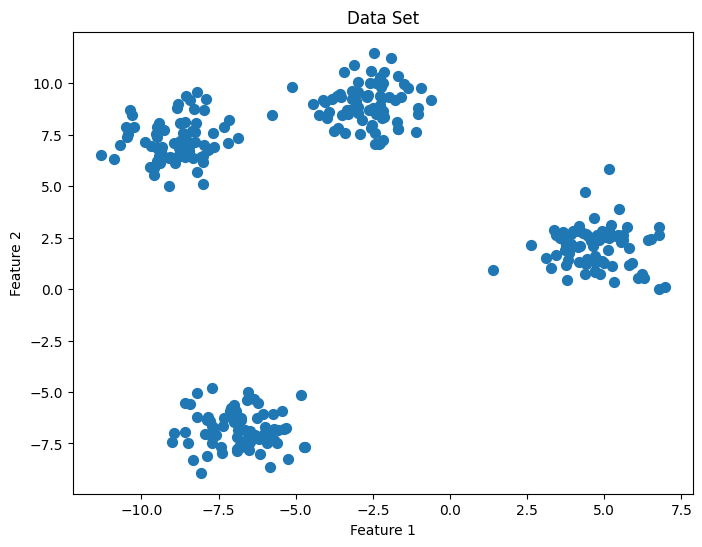

In [59]:
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1],s=50)

plt.title('Data Set')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

In [60]:
kmeans = KMeans(n_clusters=5)
kmeans.fit(X)

KMeans(n_clusters=5)

In [62]:
centers = kmeans.cluster_centers_
labels = kmeans.labels_

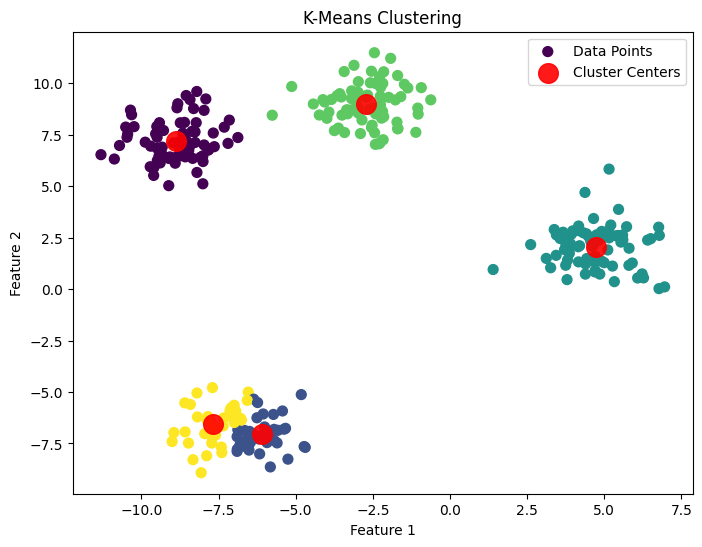

In [64]:
plt.figure(figsize=(8,6))

plt.scatter(X[:,0], X[:,1], c=labels, s=50, label="Data Points")
plt.scatter(centers[:,0], centers[:,1],c='red', s=200, alpha=0.9, label="Cluster Centers")

plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

# Hierarchical Clustering

In [67]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [69]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

x,_=make_blobs(
    n_samples=300,
    centers=4,
    random_state=42
)

In [70]:
hierarchical = linkage(X, 'single')

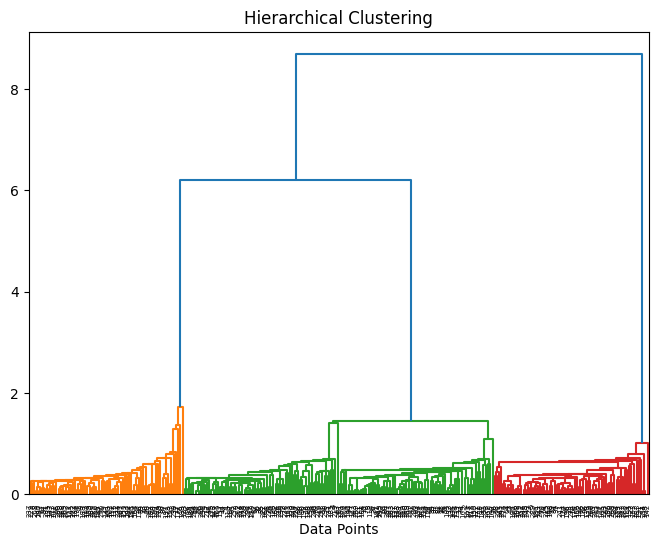

In [74]:
plt.figure(figsize=(8,6))

dendrogram(
    hierarchical,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering')
plt.xlabel('Data Points')
plt.show()


In [75]:
hierarcihal2 = linkage(X, 'complete')

clustering = fcluster(
    hierarcihal2,
    20,
    criterion='distance'
  )

In [76]:
print('Number of clusters formed: ',len(np.unique(clustering)))

Number of clusters formed:  2


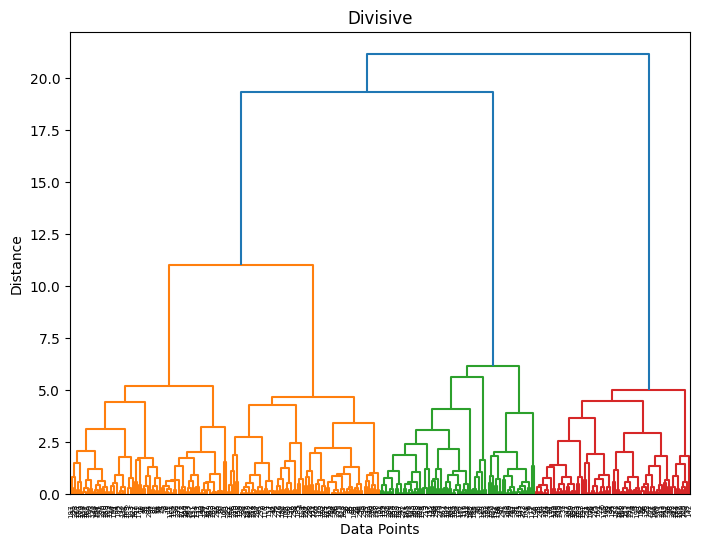

In [78]:
plt.figure(figsize=(8,6))

dendrogram(
    hierarcihal2,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True
)

plt.title('Divisive')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()